In [15]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
# f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/DXY_res_histo_inpTbins.coffea"
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/Sept5_DASK_FullFixed_inlxybins.coffea"


sig_histo = util.load(f_sig) [0]
# sig_histo

sig_2022_Mchi-11p0_dMchi-2p0_ctau-100
Hist(
  Variable([0, 2, 5, 10], name='Gen_dxy_res'),
  Regular(500, -1, 1, name='Res_LPT'),
  storage=Weight()) # Sum: WeightedSum(value=2357, variance=2357) (WeightedSum(value=2506, variance=2506) with flow)
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100
sig_2022_Mchi-33p0_dMchi-6p0_ctau-100
sig_2022_Mchi-44p0_dMchi-8p0_ctau-100
sig_2022_Mchi-55p0_dMchi-10p0_ctau-100
sig_2022_Mchi-63p0_dMchi-6p0_ctau-100
sig_2022_Mchi-66p0_dMchi-12p0_ctau-100
sig_2022_Mchi-73p5_dMchi-7p0_ctau-100
sig_2022_Mchi-77p0_dMchi-14p0_ctau-100
sig_2022_Mchi-84p0_dMchi-8p0_ctau-100
sig_2022_Mchi-88p0_dMchi-16p0_ctau-100
sig_2022_Mchi-94p5_dMchi-9p0_ctau-100
sig_2022_Mchi-99p0_dMchi-18p0_ctau-100
sig_2022_Mchi-105p0_dMchi-10p0_ctau-100
sig_2022_Mchi-110p0_dMchi-20p0_ctau-100


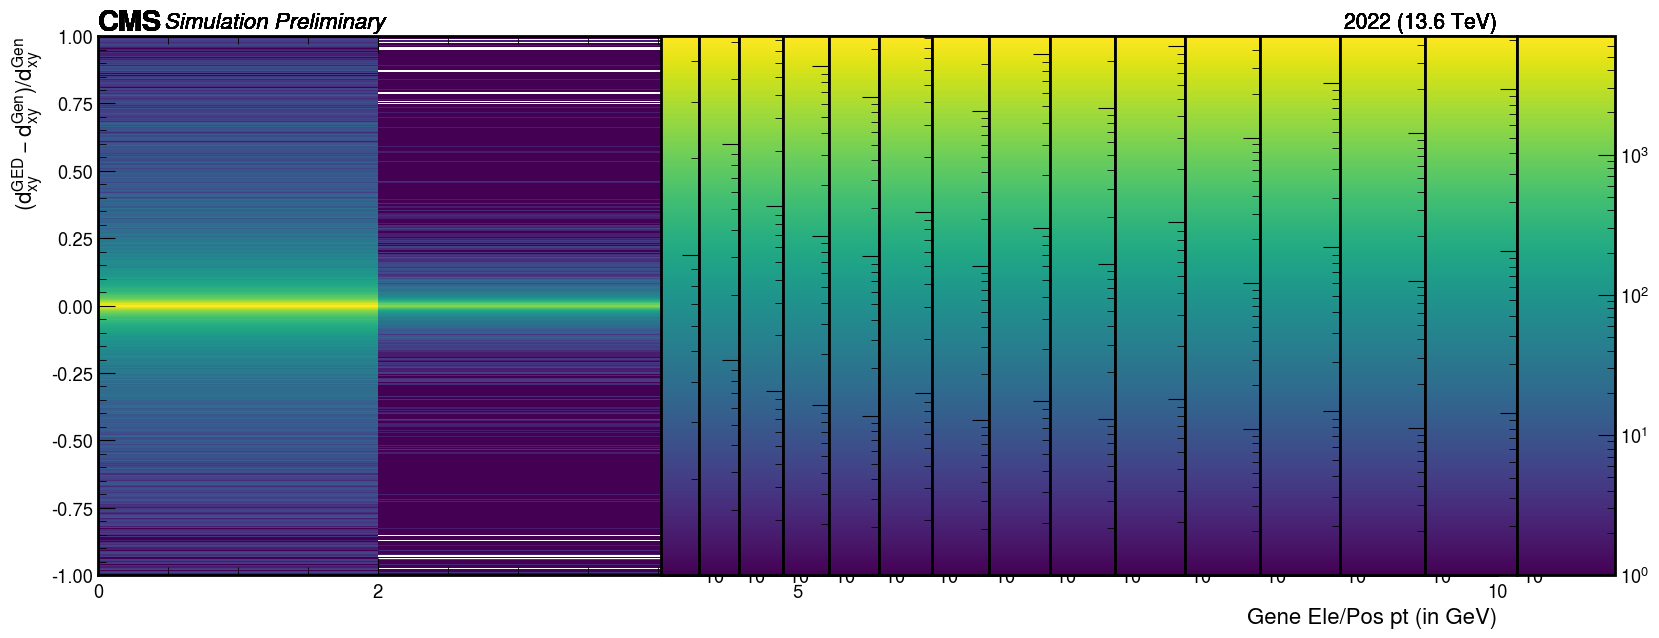

In [17]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'res_LPT_gen_ptbin',
    'cut': 'cut1',
    'year': 2022
}


style_2d_dict = {
    'fig': fig,
    'ax': ax,
    'xrebin': None,
    'yrebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]  
    'ylim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': False, 
    'doLogx': False,
    'doLogz': True,
    'xlabel': "Gene Ele/Pos pt (in GeV)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': r'$(d_{xy}^{\mathrm{GED}}-d_{xy}^{\mathrm{Gen}})/d_{xy}^{\mathrm{Gen}}$',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'zlabel': None,   
    'flow': None,     # overflow
    'doSave': False,
    'outDir': './plots/signal_2018',
    'outName': f'ptvslxy.png'
}


samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
 
}

h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt = ptools.plot_signal_2D(sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
            h_list_lpt.append(h_lpt)            
            if h_sum_lpt is None:
                h_sum_lpt = h_lpt.copy()
                print (h_sum_lpt)
            else:
                h_sum_lpt += h_lpt



# DSCB dxy-resolution fits in Gen $L_{xy}$ bins

This keeps the same basic fitting approach as the previous notebook, but makes only the changes needed to stabilize the fits:

- use the **stored 0.004 residual bin width** instead of rebinning to 0.04;
- initialize the mean and width from the central 68% of the histogram;
- determine a reasonable fit range from that core width instead of scanning many hand-written ranges;
- keep the DSCB model, but fix `nL = nR = 2` so sparse $L_{xy}$ bins do not have to determine all seven DSCB parameters independently;
- fit only the populated histogram bins inside the selected fit range, as in the original notebook.

The rest is the same idea as before: fit each Gen $L_{xy}$ bin separately, inspect the fit, and plot the fitted DSCB $\sigma$ versus Gen $L_{xy}$.


In [18]:

# ============================================================
# SETTINGS
# ============================================================

# The stored residual histogram has width 0.004.  Do NOT rebin by 10 here;
# the dxy-resolution core is too narrow for 0.04-wide bins.
RES_BIN_WIDTH = 0.004

# Only used for displaying the fit plots.
plot_min = -0.50
plot_max =  0.50

# Fix the power parameters of the two DSCB tails.  This leaves the fit with
# mean, sigma, alphaL, alphaR and normalization as free parameters.
NL_FIXED = 2.0
NR_FIXED = 2.0

print(f'Residual bin width: {RES_BIN_WIDTH}')
print(f'Fixed DSCB nL/nR : {NL_FIXED}, {NR_FIXED}')


Residual bin width: 0.004
Fixed DSCB nL/nR : 2.0, 2.0


In [19]:

# ============================================================
# Build the histogram used for the fits
# ============================================================

original_edges = h_sum_lpt.axes[1].edges
original_widths = np.diff(original_edges)

if not np.allclose(original_widths, original_widths[0]):
    raise ValueError('Residual axis is not uniformly binned.')

stored_width = original_widths[0]
rebin_factor = int(round(RES_BIN_WIDTH / stored_width))

if rebin_factor < 1:
    raise ValueError('Requested bin width is finer than the stored histogram.')

if not np.isclose(rebin_factor * stored_width, RES_BIN_WIDTH):
    raise ValueError('Requested bin width is not an integer multiple of the stored width.')

h_fit = h_sum_lpt[:, hist.rebin(rebin_factor)]

print(f'Stored residual bin width: {stored_width:g}')
print(f'Rebin factor             : {rebin_factor}')
print(f'Bin width used           : {rebin_factor*stored_width:g}')
print(f'Gen Lxy bins             : {list(h_fit.axes[0].edges)}')


Stored residual bin width: 0.004
Rebin factor             : 1
Bin width used           : 0.004
Gen Lxy bins             : [0.0, 2.0, 5.0, 10.0]


In [20]:

# ============================================================
# DSCB MODEL
# ============================================================

def double_cb(x, u, sig, nl, a_l, nr, a_r, N):
    t = (x-u)/sig
    al = abs(a_l)
    ar = abs(a_r)

    left_tail = t < -al
    core = (t >= -al) & (t <= ar)
    right_tail = t > ar

    y = np.empty_like(t)
    y[core] = np.exp(-0.5*t[core]*t[core])

    A_L = (nl/al)**nl * np.exp(-0.5*al**2)
    B_L = (nl/al) - al
    y[left_tail] = A_L / (B_L - t[left_tail])**nl

    A_R = (nr/ar)**nr * np.exp(-0.5*ar**2)
    B_R = (nr/ar) - ar
    y[right_tail] = A_R / (B_R + t[right_tail])**nr

    return N*y


In [21]:

# ============================================================
# Fit each Gen-Lxy bin
# ============================================================
from scipy.optimize import curve_fit

fit_data = []
final_fit_results = {}

n_lxy_bins = len(h_fit.axes[0].edges) - 1

for idx in range(n_lxy_bins):

    lxy_low  = h_fit.axes[0].edges[idx]
    lxy_high = h_fit.axes[0].edges[idx + 1]

    y = h_fit[idx, :].values()
    edges = h_fit.axes[1].edges
    x = 0.5 * (edges[:-1] + edges[1:])

    # --------------------------------------------------------
    # Robust starting values from the central 68% of the data
    # --------------------------------------------------------
    total = np.sum(y)
    if total <= 0:
        print(f'Gen Lxy bin {lxy_low:g}-{lxy_high:g}: empty histogram')
        continue

    cumulative = np.cumsum(y) / total
    q16 = np.interp(0.16, cumulative, x)
    q50 = np.interp(0.50, cumulative, x)
    q84 = np.interp(0.84, cumulative, x)

    mean0 = q50
    sigma68 = 0.5 * (q84 - q16)
    sigma0 = max(sigma68, RES_BIN_WIDTH)

    # Use roughly five core widths on each side, with sensible limits.
    # This replaces the long manual fit-range scan from the previous notebook.
    half_range = np.clip(5.0 * sigma0, 0.10, 0.30)
    fit_min = max(plot_min, mean0 - half_range)
    fit_max = min(plot_max, mean0 + half_range)

    # Keep the original fitting philosophy: use only populated bins
    # inside the automatically chosen fit range.
    mask = (
        np.isfinite(x) & np.isfinite(y) &
        (x >= fit_min) & (x <= fit_max) &
        (y > 0)
    )

    xfit = x[mask]
    yfit = y[mask]
    yerrfit = np.sqrt(yfit)

    # Keep the same DSCB, but fix nL and nR.  This greatly reduces the
    # instability that was giving enormous sigma uncertainties.
    model = lambda xx, u, sig, a_l, a_r, N: double_cb(
        xx, u, sig, NL_FIXED, a_l, NR_FIXED, a_r, N
    )

    initial_guess = [mean0, sigma0, 1.0, 1.0, max(yfit.max(), 1.0)]

    lower = [fit_min, RES_BIN_WIDTH/2.0, 0.20, 0.20, 0.0]
    upper = [fit_max, 0.20,                 5.00, 5.00, 10.0*max(yfit.max(),1.0)]

    try:
        popt, pcov = curve_fit(
            model,
            xfit,
            yfit,
            p0=initial_guess,
            sigma=yerrfit,
            absolute_sigma=True,
            bounds=(lower, upper),
            maxfev=50000,
        )

        perr = np.sqrt(np.diag(pcov))
        prediction = model(xfit, *popt)
        ndof = len(xfit) - len(popt)
        print ("ndof=", ndof)
        chi2 = np.sum(((yfit - prediction)/yerrfit)**2)
        chi2ndof = chi2/ndof if ndof > 0 else np.nan

        result = {
            'lxybin_range': (lxy_low, lxy_high),
            'fit_range': (fit_min, fit_max),
            'fit_mean': popt[0],
            'fit_mean_unc': perr[0],
            'fit_sigma': popt[1],
            'fit_sigma_unc': perr[1],
            'sigma68': sigma68,
            'chi2/ndof': chi2ndof,
            'popt': popt,
            'model': model,
        }

        fit_data.append(result)
        final_fit_results[idx] = result

        print(
            f'Gen Lxy {lxy_low:g}-{lxy_high:g}: '
            f'sigma = {popt[1]:.5f} +/- {perr[1]:.5f}, '
            f'sigma68 = {sigma68:.5f}, '
            f'chi2/ndof = {chi2ndof:.2f}, '
            f'fit range = ({fit_min:.3f}, {fit_max:.3f})'
        )

    except Exception as exc:
        print(f'Fit failed for Gen Lxy {lxy_low:g}-{lxy_high:g}: {exc}')


ndof= 82
Gen Lxy 0-2: sigma = 0.00594 +/- 0.00011, sigma68 = 0.03518, chi2/ndof = 11.83, fit range = (-0.178, 0.174)
ndof= 52
Gen Lxy 2-5: sigma = 0.00859 +/- 0.00012, sigma68 = 0.02268, chi2/ndof = 1.84, fit range = (-0.116, 0.111)
ndof= 121
Gen Lxy 5-10: sigma = 0.02776 +/- 0.00062, sigma68 = 0.05032, chi2/ndof = 1.69, fit range = (-0.256, 0.247)


/uscms/home/reshmar/nobackup/miniforge3/envs/coffea/lib/python3.8/site-packages/mplhep/plot.py:494: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  _e = ax.errorbar(


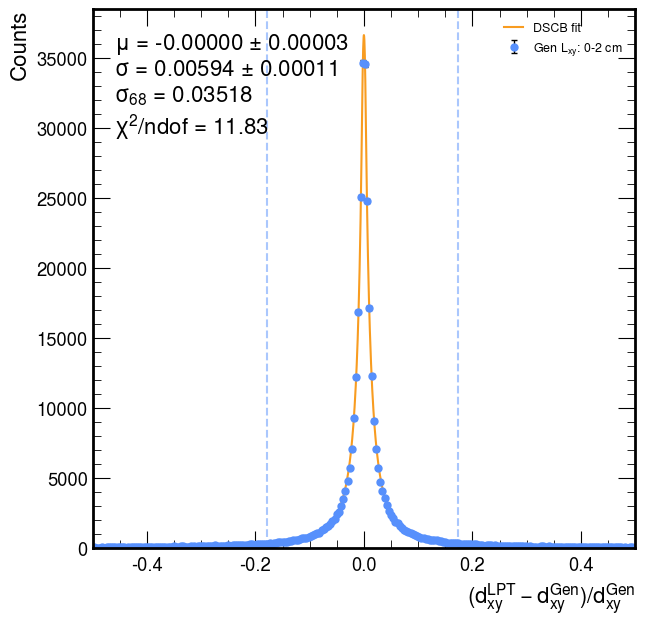

/uscms/home/reshmar/nobackup/miniforge3/envs/coffea/lib/python3.8/site-packages/mplhep/plot.py:494: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  _e = ax.errorbar(


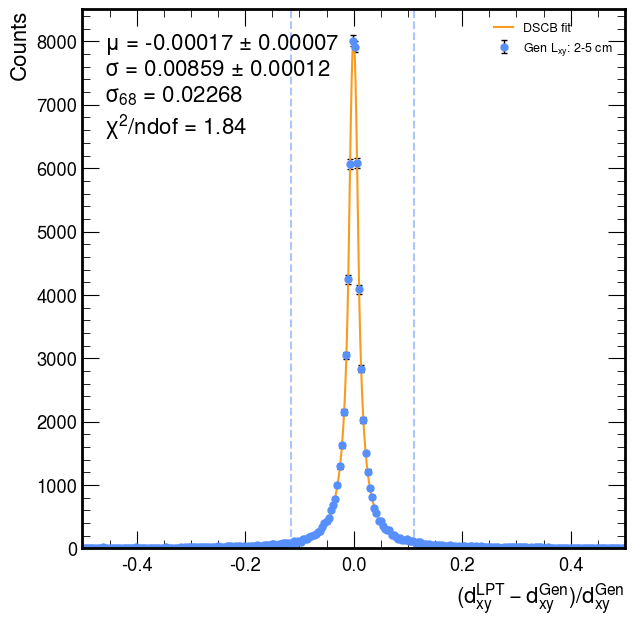

/uscms/home/reshmar/nobackup/miniforge3/envs/coffea/lib/python3.8/site-packages/mplhep/plot.py:494: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  _e = ax.errorbar(


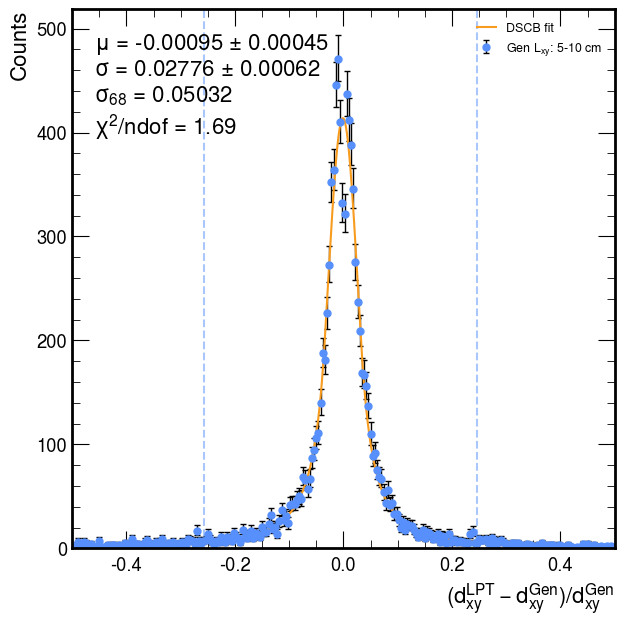

In [22]:

# ============================================================
# Plot each fitted Gen-Lxy bin
# ============================================================

for idx, result in final_fit_results.items():

    lxy_low, lxy_high = result['lxybin_range']
    y = h_fit[idx, :].values()
    edges = h_fit.axes[1].edges

    plt.figure(figsize=(7,7))

    mplhep.histplot(
        h_fit[idx, :],
        histtype='errorbar',
        yerr=True,
        fmt='o',
        capsize=2,
        ecolor='black',
        label=fr'Gen $L_{{xy}}$: {lxy_low:g}-{lxy_high:g} cm'
    )

    fit_min, fit_max = result['fit_range']
    x_curve = np.linspace(fit_min, fit_max, 800)
    plt.plot(x_curve, result['model'](x_curve, *result['popt']), label='DSCB fit')

    plt.axvline(fit_min, linestyle='--', alpha=0.5)
    plt.axvline(fit_max, linestyle='--', alpha=0.5)

    plt.xlim(plot_min, plot_max)
    plt.xlabel(r'$(d_{xy}^{LPT}-d_{xy}^{Gen})/d_{xy}^{Gen}$')
    plt.ylabel('Counts')

    plt.text(
        0.04, 0.96,
        (
            fr'$\mu$ = {result["fit_mean"]:.5f} $\pm$ {result["fit_mean_unc"]:.5f}' '\n'
            fr'$\sigma$ = {result["fit_sigma"]:.5f} $\pm$ {result["fit_sigma_unc"]:.5f}' '\n'
            fr'$\sigma_{{68}}$ = {result["sigma68"]:.5f}' '\n'
            fr'$\chi^2$/ndof = {result["chi2/ndof"]:.2f}'
        ),
        transform=plt.gca().transAxes,
        va='top'
    )

    plt.legend(fontsize=9)
    plt.show()


In [23]:

# ============================================================
# Compact fit table
# ============================================================

fit_df = pd.DataFrame([
    {
        'Gen Lxy range': item['lxybin_range'],
        'fit range': item['fit_range'],
        'mean': item['fit_mean'],
        'mean unc': item['fit_mean_unc'],
        'DSCB sigma': item['fit_sigma'],
        'sigma unc': item['fit_sigma_unc'],
        'sigma68': item['sigma68'],
        'chi2/ndof': item['chi2/ndof'],
    }
    for item in fit_data
])

display(fit_df)


,Gen Lxy range,fit range,mean,mean unc,DSCB sigma,sigma unc,sigma68,chi2/ndof
0,"(0.0, 2.0)","(-0.17797306522179424, 0.17387236446913396)",-0.000004,0.000034,0.005939,0.000115,0.035185,11.828299
1,"(2.0, 5.0)","(-0.11568912475505118, 0.11111983636553806)",-0.000173,0.000066,0.008594,0.000117,0.022681,1.839817
2,"(5.0, 10.0)","(-0.25625118635124455, 0.24694998153196746)",-0.000950,0.000453,0.027763,0.000615,0.050320,1.686540


ValueError: Size mismatch between "values" and "edges". Expected `len(values) + 1 == len(edges)`, but `len(values) = 3` and `len(edges) = 2`.

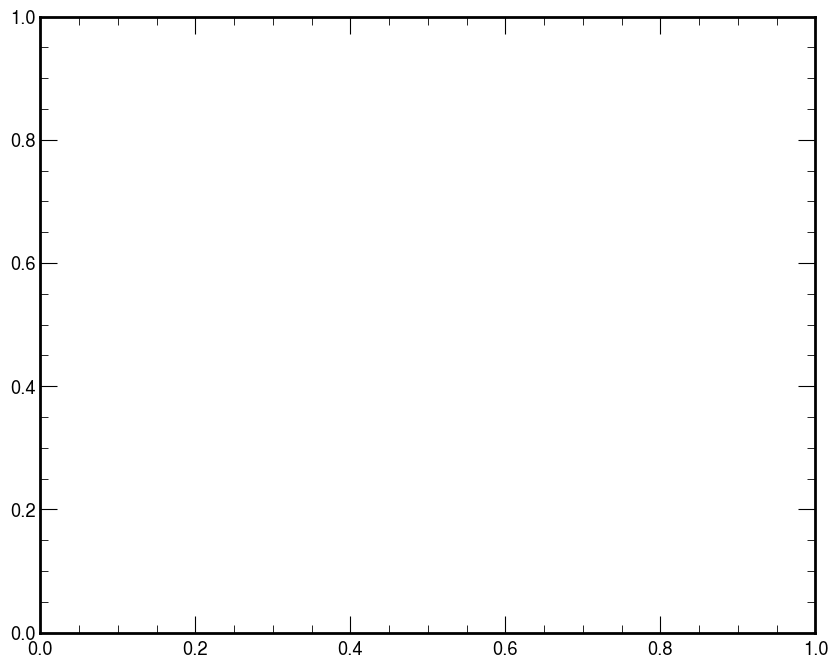

In [26]:

# ============================================================
# Final dxy resolution versus Gen Lxy
# ============================================================

lxy_centers = []
sigma = []
sigma_unc = []

for item in fit_data:
    lxy_low, lxy_high = item['lxybin_range']

    lxy_centers.append((lxy_low + lxy_high) / 2)
    sigma.append(item['fit_sigma'])
    sigma_unc.append(item['fit_sigma_unc'])

plt.figure(figsize=(10,8))
plt.stairs(sigma, item['lxybin_range'], baseline=None, label='GED')

plt.errorbar(
    lxy_centers,
    sigma,
    yerr=sigma_unc,
    fmt='o-',
    capsize=2
)

plt.xlabel(r'Gen $L_{xy}$ (cm)')
plt.ylim(0,0.08)
plt.ylabel(r'DSCB $\sigma$ of $(d_{xy}^{reco}-d_{xy}^{Gen})/d_{xy}^{Gen}$')
plt.legend()
plt.show()